# Experiment No. 09

# Title
**Implementation of K-Means Clustering Algorithm**

## Aim
To implement K-Means Clustering to divide a dataset into multiple groups based on feature similarity and analyze the resulting clusters.

## Objectives
1. Understand the working of K-Means Clustering.
2. Group similar data points into clusters.
3. Find suitable cluster centroids.
4. Select the number of clusters using the Elbow Method.
5. Visualize and evaluate the formed clusters.

## Theory
**K-Means** is an unsupervised machine learning algorithm that groups data points into K clusters. Each cluster has a centroid representing its mean position. The algorithm assigns points to the nearest centroid and repeatedly updates centroids until the clusters stabilize.

**Elbow Method:** Helps select a suitable K by observing how WCSS decreases as K increases.

**Silhouette Score:** Measures how well data points fit within their assigned clusters. A higher score generally indicates better-separated clusters.

# Step 1 - Import Required Libraries

Import the required libraries for data processing, K-Means clustering, evaluation, and visualization.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Step 2 - Generate the Dataset

Create a sample dataset containing 300 data points and three natural groups.

In [2]:
X, y_true = make_blobs(
    n_samples=300,
    centers=3,
    n_features=2,
    random_state=42
)

print("Dataset Shape:", X.shape)

Dataset Shape: (300, 2)


# Step 3 - Convert Data into a DataFrame

Convert the dataset into a Pandas DataFrame for easier analysis.

In [3]:
df = pd.DataFrame(
    X,
    columns=["Feature 1", "Feature 2"]
)

df.head()

,Feature 1,Feature 2
0,-7.338988,-7.729954
1,-7.740041,-7.264665
2,-1.686653,7.793442
3,4.422198,3.071947
4,-8.917752,-7.888196


# Step 4 - Display Dataset Information

Display the dataset structure, data types, and missing values.

In [4]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature 1  300 non-null    float64
 1   Feature 2  300 non-null    float64
dtypes: float64(2)
memory usage: 4.8 KB

Missing Values:
Feature 1    0
Feature 2    0
dtype: int64


# Step 5 - Display Dataset Statistics

Calculate the basic statistical values of the numerical features.

In [5]:
df.describe()

,Feature 1,Feature 2
count,300.000000,300.000000
mean,-1.590000,1.356727
std,4.911284,6.641879
min,-9.351272,-9.182031
25%,-6.242487,-6.311418
50%,-2.544467,1.984582
75%,3.937954,8.295815
max,6.954537,11.734455


# Step 6 - Check Duplicate Records

Check whether the dataset contains duplicate rows.

In [6]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


# Step 7 - Visualize the Original Dataset

Plot the original data points before applying K-Means clustering.

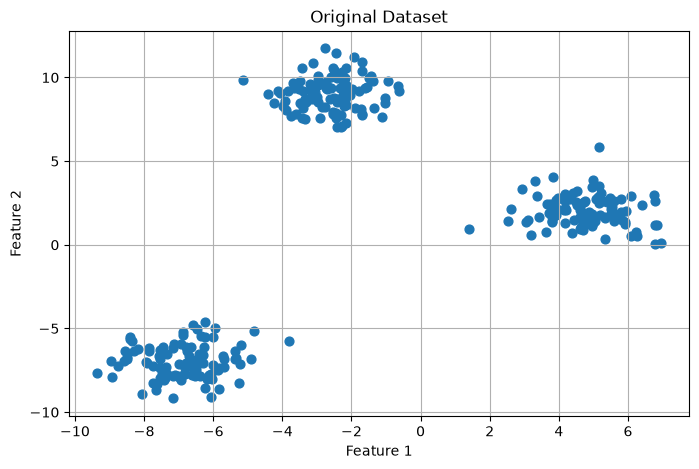

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Feature 1"],
    df["Feature 2"],
    s=40
)

plt.title("Original Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)
plt.show()

# Step 8 - Check Feature Correlation

Calculate the correlation between the two numerical features.

In [8]:
print("Feature Correlation:")
print(df.corr())

Feature Correlation:
           Feature 1  Feature 2
Feature 1   1.000000   0.413394
Feature 2   0.413394   1.000000


# Step 9 - Select Features

Select the numerical features that will be used for clustering.

In [9]:
X = df[["Feature 1", "Feature 2"]]

print("Selected Features:")
print(X.head())

Selected Features:
   Feature 1  Feature 2
0  -7.338988  -7.729954
1  -7.740041  -7.264665
2  -1.686653   7.793442
3   4.422198   3.071947
4  -8.917752  -7.888196


# Step 10 - Standardize the Features

Standardize the features because K-Means uses distances to assign data points to clusters.

In [10]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardized Data Shape:", X_scaled.shape)

Standardized Data Shape: (300, 2)


# Step 11 - Calculate WCSS for Different K Values

Train K-Means models for K values from 1 to 10 and calculate their WCSS values.

In [11]:
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    wcss.append(model.inertia_)

print("WCSS Values:")
print(wcss)

WCSS Values:
[599.9999999999999, 187.7999194617591, 18.26315933089595, 15.455336312434499, 12.715907526929657, 10.690463801076879, 9.481197524069948, 8.372879644023598, 7.41934494268391, 6.680035619861524]


# Step 12 - Plot the Elbow Curve

Plot WCSS against K to identify a possible suitable number of clusters.

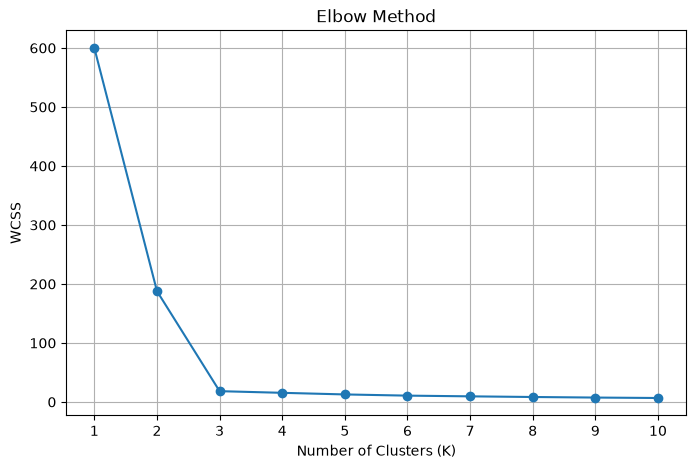

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# Step 13 - Select the Number of Clusters

Choose K based on the Elbow Method. This generated dataset is designed to contain three groups.

In [13]:
optimal_k = 3

print("Selected Number of Clusters:", optimal_k)

Selected Number of Clusters: 3


# Step 14 - Create the K-Means Model

Initialize the K-Means model with three clusters and K-Means++ initialization.

In [14]:
kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    random_state=42,
    n_init=10
)

print("K-Means Model Created Successfully")

K-Means Model Created Successfully


# Step 15 - Train the K-Means Model

Fit the K-Means model to the standardized dataset.

In [15]:
kmeans.fit(X_scaled)

print("K-Means Model Trained Successfully")

K-Means Model Trained Successfully


# Step 16 - Predict Cluster Labels

Assign every data point to its nearest cluster centroid.

In [16]:
labels = kmeans.labels_

print("First 20 Cluster Labels:")
print(labels[:20])

First 20 Cluster Labels:
[1 1 0 2 1 2 0 2 0 0 0 2 0 0 1 0 1 2 0 0]


# Step 17 - Add Cluster Labels to the Dataset

Add the predicted cluster label to each row of the original dataset.

In [17]:
df["Cluster"] = labels

print("Clustered Dataset:")
print(df.head())

Clustered Dataset:
   Feature 1  Feature 2  Cluster
0  -7.338988  -7.729954        1
1  -7.740041  -7.264665        1
2  -1.686653   7.793442        0
3   4.422198   3.071947        2
4  -8.917752  -7.888196        1


# Step 18 - Display Cluster Centroids

Display the centroids calculated by K-Means in standardized feature space.

In [18]:
centroids_scaled = kmeans.cluster_centers_

print("Cluster Centroids:")
print(centroids_scaled)

Cluster Centroids:
[[-0.21277029  1.15926337]
 [-1.07970061 -1.25787405]
 [ 1.2924709   0.09861068]]


# Step 19 - Convert Centroids to Original Scale

Convert the centroids back to the original feature scale for easier interpretation.

In [19]:
centroids_original = scaler.inverse_transform(
    centroids_scaled
)

centroid_df = pd.DataFrame(
    centroids_original,
    columns=["Feature 1", "Feature 2"]
)

print("Centroids in Original Scale:")
print(centroid_df)

Centroids in Original Scale:
   Feature 1  Feature 2
0  -2.633233   9.043570
1  -6.883872  -6.983984
2   4.747103   2.010594


# Step 20 - Visualize the Clusters

Display the clustered data points using different colors for each cluster.

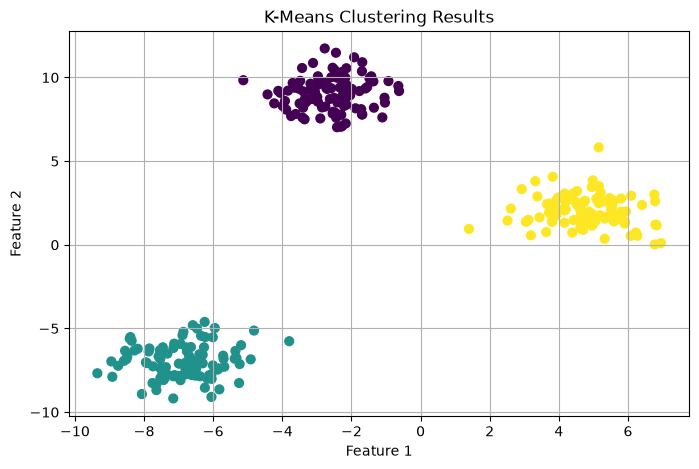

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X["Feature 1"],
    X["Feature 2"],
    c=labels,
    cmap="viridis",
    s=40
)

plt.title("K-Means Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True)
plt.show()

# Step 21 - Visualize Clusters with Centroids

Plot the clusters and highlight their centroids using black cross markers.

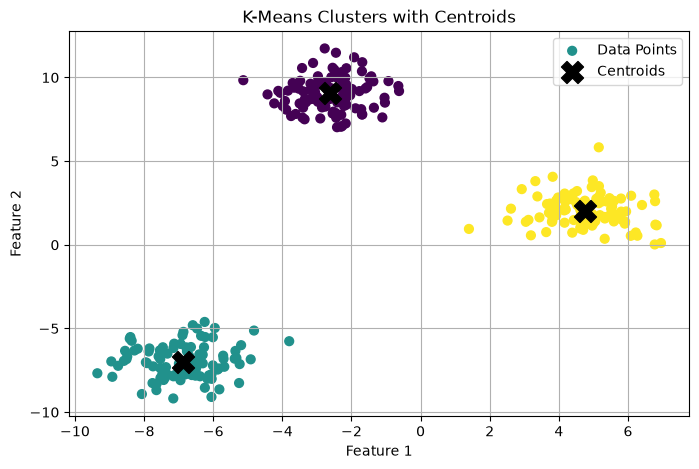

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X["Feature 1"],
    X["Feature 2"],
    c=labels,
    cmap="viridis",
    s=40,
    label="Data Points"
)

plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    marker="X",
    s=250,
    c="black",
    label="Centroids"
)

plt.title("K-Means Clusters with Centroids")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

# Step 22 - Count Data Points in Each Cluster

Count the number of data points assigned to each cluster.

In [22]:
cluster_counts = (
    df["Cluster"]
    .value_counts()
    .sort_index()
)

print("Data Points in Each Cluster:")
print(cluster_counts)

Data Points in Each Cluster:
Cluster
0    100
1    100
2    100
Name: count, dtype: int64


# Step 23 - Calculate Final WCSS

Display the final WCSS value of the trained K-Means model.

In [23]:
print("Final WCSS:", kmeans.inertia_)

Final WCSS: 18.26315933089595


# Step 24 - Calculate Silhouette Score

Calculate the Silhouette Score to evaluate how well the clusters are separated.

In [24]:
score = silhouette_score(
    X_scaled,
    labels
)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.8482


# Step 25 - Compare Silhouette Scores for Different K Values

Calculate the Silhouette Score for K values from 2 to 10.

In [25]:
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    cluster_labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        cluster_labels
    )

    silhouette_scores.append(score)

results = pd.DataFrame({
    "K": range(2, 11),
    "Silhouette Score": silhouette_scores
})

print(results)

    K  Silhouette Score
0   2          0.687532
1   3          0.848233
2   4          0.679458
3   5          0.521874
4   6          0.357454
5   7          0.370935
6   8          0.373594
7   9          0.353592
8  10          0.368962


# Step 26 - Plot Silhouette Scores

Visualize the Silhouette Scores for different values of K.

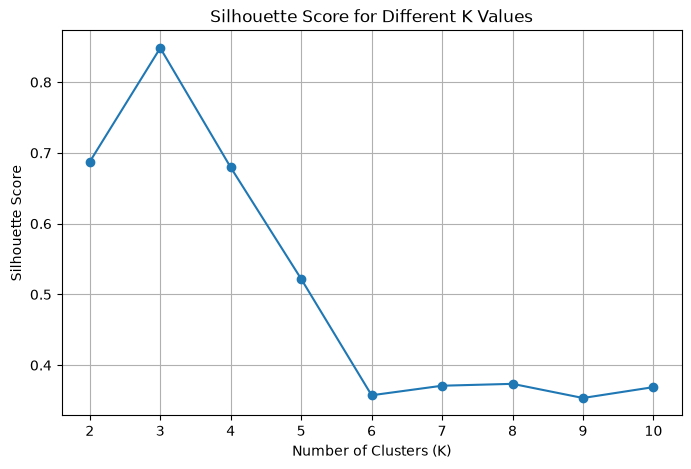

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

# Step 27 - Find the Highest Silhouette Score

Identify the tested K value that produces the highest Silhouette Score.

In [27]:
best_index = np.argmax(silhouette_scores)

best_k = list(range(2, 11))[best_index]
best_score = silhouette_scores[best_index]

print("Best K by Silhouette Score:", best_k)
print("Highest Silhouette Score:", round(best_score, 4))

Best K by Silhouette Score: 3
Highest Silhouette Score: 0.8482


# Step 28 - Display the Final Clustered Dataset

Display the original features together with their assigned cluster labels.

In [28]:
print("Final Clustered Dataset:")
display(df.head(10))

Final Clustered Dataset:


,Feature 1,Feature 2,Cluster
0,-7.338988,-7.729954,1
1,-7.740041,-7.264665,1
2,-1.686653,7.793442,0
3,4.422198,3.071947,2
4,-8.917752,-7.888196,1
5,5.497538,1.813231,2
6,-2.336017,9.399604,0
7,5.052810,1.409445,2
8,-2.988372,8.828627,0
9,-3.700501,9.670840,0


# Step 29 - Visualize Cluster Distribution

Create a bar chart showing the number of data points in each cluster.

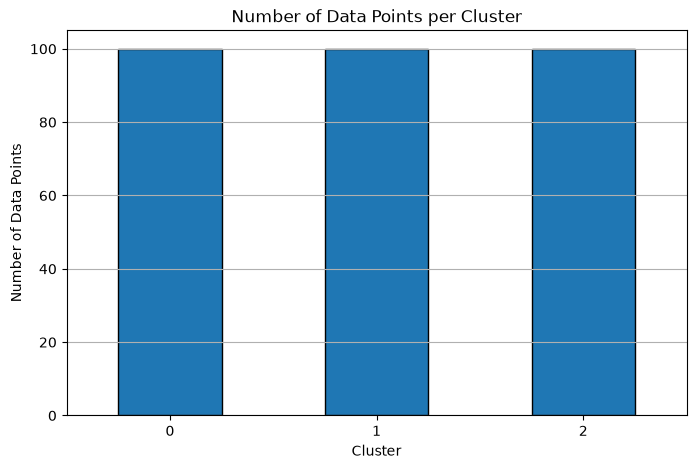

In [29]:
plt.figure(figsize=(8, 5))

cluster_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Number of Data Points per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Data Points")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

# Step 30 - Predict the Cluster of a New Data Point

Use the trained K-Means model to assign a new data point to a cluster.

In [30]:
new_point = pd.DataFrame(
    [[0, 0]],
    columns=["Feature 1", "Feature 2"]
)

new_point_scaled = scaler.transform(new_point)

predicted_cluster = kmeans.predict(
    new_point_scaled
)

print("New Data Point:")
print(new_point)

print("Predicted Cluster:", predicted_cluster[0])

New Data Point:
   Feature 1  Feature 2
0          0          0
Predicted Cluster: 2


## Result

The K-Means Clustering algorithm was implemented successfully. The dataset was grouped into clusters based on feature similarity. The Elbow Method was used to examine the number of clusters, centroids were calculated and visualized, and the Silhouette Score was used to evaluate cluster separation.